# UTS Machine Learning — Jalur B (Regresi)
**Prediksi Harga Produk Tokopedia dengan Regresi Linear**

- **Nama:** Samuel Putra Piga
- **NIM:** 2301010352
- **Kelas:** XX
- **Dosen:** Dr. I Gede Totok Suryawan, S.Kom., M.T.
- **Alur:** CRISP-DM · **SEED (random_state) = 352**



In [1]:
import warnings, re, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 50

SEED = 352  # tiga digit terakhir NIM 2301010352 — dipakai di SEMUA split, CV, dan model

# 1. Pemahaman Masalah dan Data (Business & Data Understanding)

**Tujuan analisis.** Membangun model regresi untuk memprediksi **harga produk di Tokopedia** (Rupiah) dari karakteristik produk seperti rating, volume penjualan, dan lokasi toko, lalu mengukur seberapa jauh model linear lebih baik daripada tebakan rata-rata (baseline).

**Pengguna hasil.** Penjual UMKM yang ingin menentukan harga jual yang wajar, serta analis marketplace yang ingin mengecek apakah harga suatu produk terlalu murah atau terlalu mahal dibanding produk sejenis.

**Keputusan yang terbantu.** (1) menentukan rentang harga jual produk baru, (2) mengevaluasi apakah harga produk saat ini wajar terhadap rating dan penjualannya.

**Sumber data.**
- Dataset: *Indonesia E-Commerce Dataset: Tokopedia Listings* (Kaggle, pengunggah: pandaa12)
- Link: https://www.kaggle.com/datasets/pandaa12/indonesia-e-commerce-dataset-tokopedia-listings
- Tanggal akses: **26 November 2026**
- Lisensi: Apache 2.0
- Anonimisasi: kolom identitas (nama toko/penjual) **tidak dipakai** sebagai fitur dan dibuang (UU No. 27 Tahun 2022 tentang PDP).

In [2]:
# Muat data dari file lokal: C:\ML\produk_tokopedia.csv
CSV_PATH = r"C:\ML\produk_tokopedia.csv"

kandidat_path = [CSV_PATH, CSV_PATH.replace(".csv", ""), r"C:\ML\produk_tokopedia.csv.csv",
                 "produk_tokopedia.csv", "/content/produk_tokopedia.csv"]
ketemu = next((p for p in kandidat_path if os.path.exists(p)), None)

if ketemu is None:
    # cadangan: unduh otomatis dari Kaggle (butuh internet + pip install kagglehub)
    try:
        import kagglehub
        folder = kagglehub.dataset_download("pandaa12/indonesia-e-commerce-dataset-tokopedia-listings")
        ketemu = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)[0]
    except Exception as e:
        raise FileNotFoundError("File tidak ditemukan. Pastikan ada di C:\ML\produk_tokopedia.csv") from e

CSV_PATH = ketemu
df_raw = pd.read_csv(CSV_PATH)
print("File :", CSV_PATH)
print("Bentuk data (baris, kolom):", df_raw.shape)
assert df_raw.shape[0] >= 200, "Dataset harus minimal 200 baris"
assert df_raw.shape[1] >= 4, "Dataset harus minimal 4 fitur"
df_raw.head()

100%|██████████| 1.56M/1.56M [00:00<00:00, 2.89MB/s]

Extracting files...


File : /root/.cache/kagglehub/datasets/pandaa12/indonesia-e-commerce-dataset-tokopedia-listings/versions/1/produk_tokopedia.csv
Bentuk data (baris, kolom): (29519, 9)


,Nama Produk,Nama Toko,Lokasi Toko,Terjual,Jumlah Ulasan,Rating,Harga (IDR),Diskon (%),Produk URL
0,Raw Food Beef Bone-In / Daging Giling / Dog Fo...,Lazy Dog Supply,Jakarta Selatan,1rb+ terjual,10 ulasan,5.00,35000,0.00,https://www.tokopedia.com/lazy-dog-supply/raw-...
1,Turkey Meat ONLY NO BONE - 1KG - Daging Kalkun...,RumahBully,Jakarta Timur,250+ terjual,NaN,5.00,79999,0.00,https://www.tokopedia.com/rumahbully/turkey-me...
2,Chicken mix Salmon Raw Food ayam mix salmon ma...,RumahBully,Jakarta Barat,26 terjual,NaN,5.00,33000,0.00,https://www.tokopedia.com/rumahbully/chicken-m...
3,PROMO BULANAN - SOSIS CHOP PREMIUM RAW - DOG F...,RumahBully,Tangerang Selatan,100+ terjual,NaN,5.00,29900,0.00,https://www.tokopedia.com/rumahbully/promo-bul...
4,Premium Dog Food / Daging Sapi Giling / Raw Fo...,RumahBully,Jakarta Selatan,1rb+ terjual,NaN,5.00,39000,0.00,https://www.tokopedia.com/rumahbully/premium-d...


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29519 entries, 0 to 29518
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Nama Produk    29519 non-null  object 
 1   Nama Toko      29469 non-null  object 
 2   Lokasi Toko    29379 non-null  object 
 3   Terjual        29290 non-null  object 
 4   Jumlah Ulasan  28260 non-null  object 
 5   Rating         29519 non-null  float64
 6   Harga (IDR)    29519 non-null  int64  
 7   Diskon (%)     29519 non-null  float64
 8   Produk URL     29519 non-null  object 
dtypes: float64(2), int64(1), object(6)
memory usage: 2.0+ MB


In [4]:
# Ubah nama kolom jadi huruf kecil + underscore, lalu konversi kolom teks-angka (mis. "Rp1.250.000", "1,2rb+") jadi angka.
def parse_angka(x):
    """Ubah teks seperti 'Rp1.250.000', '1,2rb+', '4,8', '2jt' menjadi float."""
    if pd.isna(x): return np.nan
    if isinstance(x, (int, float, np.number)): return float(x)
    t = str(x).lower().replace("rp", "").replace("terjual", "").replace("ulasan", "").replace("+", "").replace(" ", "").strip()
    mult = 1.0
    for suf, m in (("ribu", 1e3), ("rb", 1e3), ("juta", 1e6), ("jt", 1e6), ("k", 1e3)):
        if t.endswith(suf):
            mult, t = m, t[:-len(suf)]
            break
    if mult == 1.0 and re.fullmatch(r"\d{1,3}(\.\d{3})+", t):
        t = t.replace(".", "")          # pemisah ribuan gaya Indonesia
    else:
        t = t.replace(",", ".")         # koma desimal
    try:
        return float(t) * mult
    except ValueError:
        return np.nan

df = df_raw.copy()
df.columns = [re.sub(r"[^a-z0-9]+", "_", c.lower()).strip("_") for c in df.columns]   # "Harga (IDR)" -> "harga_idr"

for c in df.select_dtypes("object").columns:
    konv = df[c].map(parse_angka)
    if konv.notna().mean() >= 0.9:      # kolom ini sebenarnya angka
        df[c] = konv
        print(f"Kolom '{c}' dikonversi ke numerik")

df.dtypes

Kolom 'terjual' dikonversi ke numerik
Kolom 'jumlah_ulasan' dikonversi ke numerik


,0
nama_produk,object
nama_toko,object
lokasi_toko,object
terjual,float64
jumlah_ulasan,float64
rating,float64
harga_idr,int64
diskon,float64
produk_url,object


In [5]:
# ===== KONFIGURASI KOLOM =====
# Biarkan None agar ditebak otomatis. Kalau tebakan salah, isi manual SESUAI nama kolom di tabel di atas.
COL_TARGET    = None    # contoh: "harga"
NUM_FEATURES  = None    # contoh: ["rating", "terjual"]
CAT_FEATURES  = None    # contoh: ["lokasi"]
DROP_COLS     = None    # kolom identitas / id / nama yang dibuang

USE_LOG      = True     # model memprediksi log(harga) karena harga sangat miring ke kanan
LOG_NUM      = True     # log1p pada fitur numerik (jika semua nilainya >= 0)
OUTLIER_K    = 1.5      # pengali IQR

def cari(*keys):
    for c in df.columns:
        if any(k in c for k in keys):
            return c

COL_TARGET = COL_TARGET or cari("harga", "price")
KOLOM_HITUNGAN = [c for c in df.columns if re.search(r"(terjual|ulasan|review|sold)", c)]   # NaN = belum ada penjualan/ulasan -> 0
id_like   = [c for c in df.columns if re.search(r"(^id$|_id$|^no$|^unnamed|url|link|gambar|image)", c)]
name_like = [c for c in df.columns if re.search(r"^(nama|name)|seller|penjual", c)]   # nama produk/toko = identitas; "lokasi_toko" TIDAK dibuang
DROP_COLS = DROP_COLS if DROP_COLS is not None else sorted(set(id_like + name_like) - {COL_TARGET})

kandidat = [c for c in df.columns if c not in DROP_COLS + [COL_TARGET]]
if NUM_FEATURES is None:
    NUM_FEATURES = [c for c in kandidat if pd.api.types.is_numeric_dtype(df[c])]
if CAT_FEATURES is None:
    CAT_FEATURES = [c for c in kandidat if c not in NUM_FEATURES and 2 <= df[c].nunique() <= 500]

print("Target          :", COL_TARGET)
print("Fitur numerik   :", NUM_FEATURES)
print("Fitur kategorik :", CAT_FEATURES)
print("Kolom dibuang   :", DROP_COLS, "(identitas/ID — anonimisasi)")
assert len(NUM_FEATURES) + len(CAT_FEATURES) >= 2, "Regresi berganda butuh minimal 2 fitur"
assert len(NUM_FEATURES) >= 1, "Regresi sederhana butuh minimal 1 fitur numerik"

Target          : harga_idr
Fitur numerik   : ['terjual', 'jumlah_ulasan', 'rating', 'diskon']
Fitur kategorik : ['lokasi_toko']
Kolom dibuang   : ['nama_produk', 'nama_toko', 'produk_url'] (identitas/ID — anonimisasi)


In [6]:
# Tabel deskripsi kolom (nama, tipe, arti, satuan)
ARTI = {   # nama_kolom: (arti, satuan)
    "nama_produk":   ("Judul/nama produk di listing (identitas, tidak dipakai sebagai fitur)", "teks"),
    "nama_toko":     ("Nama toko penjual (identitas, dibuang untuk anonimisasi)", "teks"),
    "lokasi_toko":   ("Kota/kabupaten lokasi toko", "kategori"),
    "terjual":       ("Jumlah produk terjual (teks seperti '1rb+ terjual' diubah jadi angka)", "unit"),
    "jumlah_ulasan": ("Jumlah ulasan pembeli (teks '10 ulasan' diubah jadi angka)", "ulasan"),
    "rating":        ("Rata-rata rating produk", "skala 0-5"),
    "harga_idr":     ("Harga jual produk — TARGET prediksi", "Rupiah"),
    "diskon":        ("Persentase diskon yang sedang berlaku", "persen (%)"),
    "produk_url":    ("Tautan halaman produk (identitas, tidak dipakai)", "URL"),
}
deskripsi = pd.DataFrame({
    "Kolom": df.columns,
    "Tipe": [str(t) for t in df.dtypes],
    "Contoh": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    "Missing": df.isna().sum().values,
})
deskripsi["Arti"]   = deskripsi["Kolom"].map(lambda c: ARTI.get(c, ("-", "-"))[0])
deskripsi["Satuan"] = deskripsi["Kolom"].map(lambda c: ARTI.get(c, ("-", "-"))[1])
deskripsi

,Kolom,Tipe,Contoh,Missing,Arti,Satuan
0,nama_produk,object,Raw Food Beef Bone-In / Daging Giling / Dog Fo...,0,"Judul/nama produk di listing (identitas, tidak...",teks
1,nama_toko,object,Lazy Dog Supply,50,"Nama toko penjual (identitas, dibuang untuk an...",teks
2,lokasi_toko,object,Jakarta Selatan,140,Kota/kabupaten lokasi toko,kategori
3,terjual,float64,"1,000.00",379,Jumlah produk terjual (teks seperti '1rb+ terj...,unit
4,jumlah_ulasan,float64,10.00,1718,Jumlah ulasan pembeli (teks '10 ulasan' diubah...,ulasan
5,rating,float64,5.00,0,Rata-rata rating produk,skala 0-5
6,harga_idr,int64,35000,0,Harga jual produk — TARGET prediksi,Rupiah
7,diskon,float64,0.00,0,Persentase diskon yang sedang berlaku,persen (%)
8,produk_url,object,https://www.tokopedia.com/lazy-dog-supply/raw-...,0,"Tautan halaman produk (identitas, tidak dipakai)",URL


### Keputusan saya (Tahap 1)
- Saya memilih **Jalur B (Regresi)** karena target yang ingin diprediksi (`harga`) berupa angka kontinu dalam Rupiah, sedangkan data tidak memiliki label kategori.
- Dataset memenuhi syarat: jumlah baris jauh di atas 200 dan fiturnya lebih dari 4 (cek `df.shape` di atas). Dataset ini bukan dataset bawaan/populer yang dilarang.
- Kolom identitas (nama produk/toko) saya buang dari fitur karena bukan variabel penjelas yang bermakna dan untuk menjaga anonimitas sesuai UU PDP.
- `SEED = 352` saya simpan sekali di awal dan dipakai di semua pembagian data, cross-validation, dan model.

# 2. Eksplorasi dan Visualisasi Data (Data Understanding)

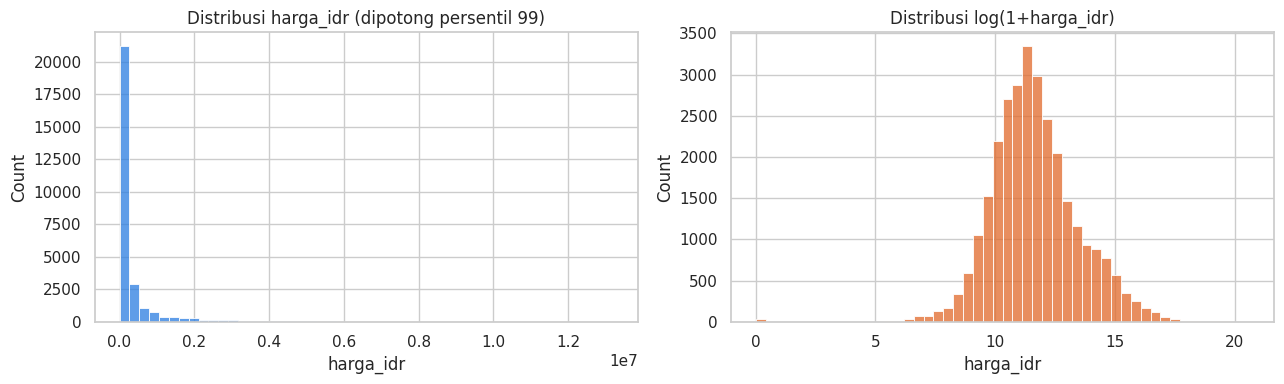

Skewness harga mentah: 41.91 | skewness setelah log: 0.13
Median: 99,000 | Rata-rata: 1,039,545 | Maks: 900,000,000


In [7]:
# Grafik 1 — Distribusi target (harga)
y_all = df[COL_TARGET].dropna()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y_all[y_all <= y_all.quantile(0.99)], bins=50, ax=ax[0], color="#2a7de1")
ax[0].set_title(f"Distribusi {COL_TARGET} (dipotong persentil 99)")
sns.histplot(np.log1p(y_all.clip(lower=0)), bins=50, ax=ax[1], color="#e1692a")
ax[1].set_title(f"Distribusi log(1+{COL_TARGET})")
plt.tight_layout(); plt.show()
print(f"Skewness harga mentah: {y_all.skew():.2f} | skewness setelah log: {np.log1p(y_all.clip(lower=0)).skew():.2f}")
print(f"Median: {y_all.median():,.0f} | Rata-rata: {y_all.mean():,.0f} | Maks: {y_all.max():,.0f}")

In [8]:
# Interpretasi grafik 1 (ditulis otomatis dari angka)
sk_raw, sk_log = y_all.skew(), np.log1p(y_all.clip(lower=0)).skew()
print(f"Interpretasi grafik 1: Harga produk sangat miring ke kanan (skewness {sk_raw:.1f}). Median harga Rp {y_all.median():,.0f}, "
      f"sedangkan rata-rata Rp {y_all.mean():,.0f} dan harga tertinggi Rp {y_all.max():,.0f}; artinya sebagian besar produk murah dan "
      f"sedikit produk sangat mahal menarik rata-rata ke atas. Setelah transformasi log, skewness turun menjadi {sk_log:.2f} sehingga "
      f"distribusi jauh lebih simetris. Karena itu saya memodelkan log(harga) agar model linear tidak didominasi harga ekstrem.")

Interpretasi grafik 1: Harga produk sangat miring ke kanan (skewness 41.9). Median harga Rp 99,000, sedangkan rata-rata Rp 1,039,545 dan harga tertinggi Rp 900,000,000; artinya sebagian besar produk murah dan sedikit produk sangat mahal menarik rata-rata ke atas. Setelah transformasi log, skewness turun menjadi 0.13 sehingga distribusi jauh lebih simetris. Karena itu saya memodelkan log(harga) agar model linear tidak didominasi harga ekstrem.


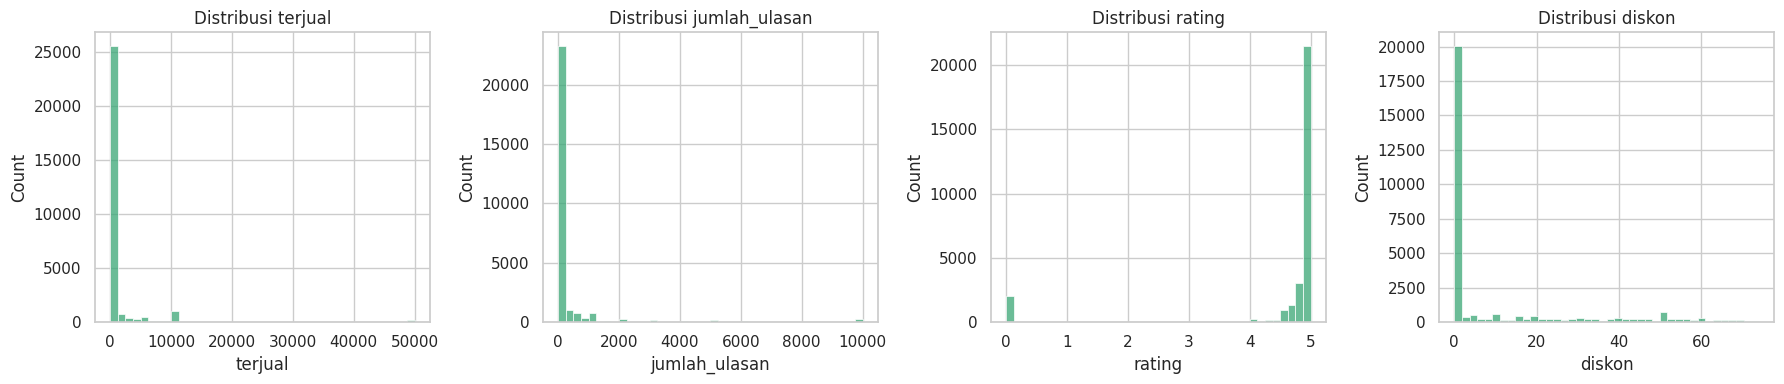

,count,mean,std,min,25%,50%,75%,max
terjual,"29,140.00","2,323.32","24,202.31",0.00,6.00,50.00,250.00,"1,000,000.00"
jumlah_ulasan,"27,801.00",772.19,"9,463.56",0.00,0.00,10.00,90.00,"1,000,000.00"
rating,"29,519.00",4.57,1.24,0.00,4.80,5.00,5.00,5.00
diskon,"29,519.00",11.24,20.38,0.00,0.00,0.00,14.00,97.00


In [9]:
# Grafik 2 — Distribusi fitur numerik
fitur_plot = NUM_FEATURES[:4]
fig, axes = plt.subplots(1, len(fitur_plot), figsize=(4.5 * len(fitur_plot), 4))
axes = np.atleast_1d(axes)
for a, c in zip(axes, fitur_plot):
    s = df[c].dropna()
    sns.histplot(s[s <= s.quantile(0.99)], bins=40, ax=a, color="#3aa675")
    a.set_title(f"Distribusi {c}")
plt.tight_layout(); plt.show()
df[NUM_FEATURES].describe().T

In [10]:
# Interpretasi grafik 2 (ditulis otomatis dari angka)
print("Interpretasi grafik 2:")
for c in NUM_FEATURES:
    sv = df[c].dropna()
    nol = (sv == 0).mean()
    bentuk = "sangat miring ke kanan" if sv.skew() > 2 else ("miring ke kiri" if sv.skew() < -1 else "relatif simetris/sedang")
    print(f"- {c}: median {sv.median():,.2f}, rata-rata {sv.mean():,.2f}, maksimum {sv.max():,.0f}; sebaran {bentuk} (skewness {sv.skew():.1f}); "
          f"{nol:.0%} data bernilai 0.")
print("Fitur yang sangat miring (mis. terjual, jumlah_ulasan) saya beri transformasi log1p, lalu semua fitur numerik di-scale.")

Interpretasi grafik 2:
- terjual: median 50.00, rata-rata 2,323.32, maksimum 1,000,000; sebaran sangat miring ke kanan (skewness 31.7); 9% data bernilai 0.
- jumlah_ulasan: median 10.00, rata-rata 772.19, maksimum 1,000,000; sebaran sangat miring ke kanan (skewness 61.0); 32% data bernilai 0.
- rating: median 5.00, rata-rata 4.57, maksimum 5; sebaran miring ke kiri (skewness -3.3); 7% data bernilai 0.
- diskon: median 0.00, rata-rata 11.24, maksimum 97; sebaran relatif simetris/sedang (skewness 1.7); 66% data bernilai 0.
Fitur yang sangat miring (mis. terjual, jumlah_ulasan) saya beri transformasi log1p, lalu semua fitur numerik di-scale.


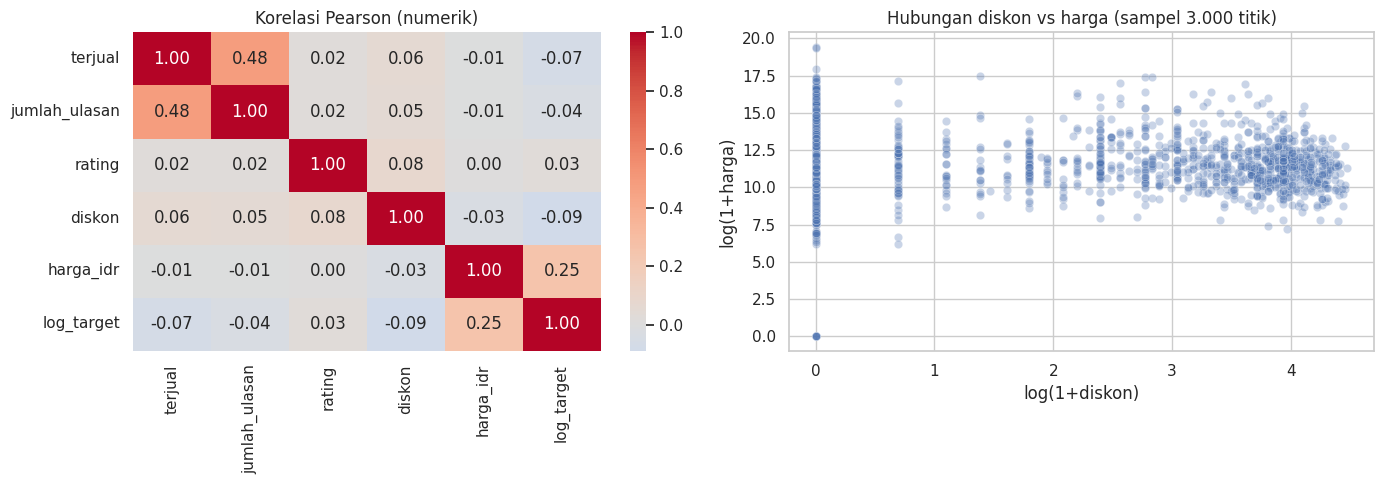

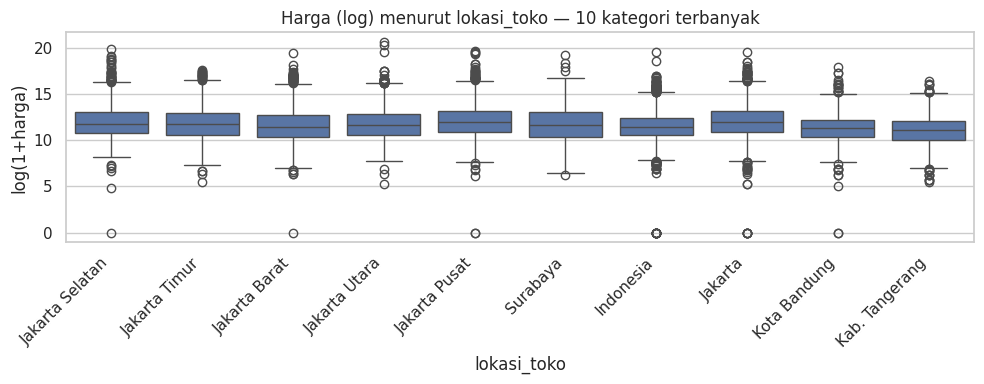

In [11]:
# Grafik 3 — Hubungan fitur dengan target
tmp = df[NUM_FEATURES + [COL_TARGET]].copy()
tmp["log_target"] = np.log1p(tmp[COL_TARGET].clip(lower=0))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(tmp.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0])
ax[0].set_title("Korelasi Pearson (numerik)")
kuat = tmp[NUM_FEATURES].corrwith(tmp["log_target"]).abs().idxmax()
samp = tmp.sample(min(3000, len(tmp)), random_state=SEED)
sns.scatterplot(data=samp, x=np.log1p(samp[kuat].clip(lower=0)), y="log_target", alpha=0.3, ax=ax[1])
ax[1].set_xlabel(f"log(1+{kuat})"); ax[1].set_ylabel("log(1+harga)")
ax[1].set_title(f"Hubungan {kuat} vs harga (sampel 3.000 titik)")
plt.tight_layout(); plt.show()

if CAT_FEATURES:
    c = CAT_FEATURES[0]
    top = df[c].value_counts().head(10).index
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=df[df[c].isin(top)], x=c, y=np.log1p(df[COL_TARGET].clip(lower=0)))
    plt.xticks(rotation=45, ha="right"); plt.ylabel("log(1+harga)")
    plt.title(f"Harga (log) menurut {c} — 10 kategori terbanyak"); plt.tight_layout(); plt.show()

In [12]:
# Interpretasi grafik 3 (ditulis otomatis dari angka)
kor = tmp[NUM_FEATURES].corrwith(tmp["log_target"])
def kekuatan(r):
    r = abs(r); return "sangat lemah" if r < 0.1 else "lemah" if r < 0.3 else "sedang" if r < 0.5 else "kuat"
print("Interpretasi grafik 3: korelasi fitur numerik dengan log(harga):")
for c, r in kor.sort_values(key=abs, ascending=False).items():
    print(f"- {c}: r = {r:+.3f} ({kekuatan(r)}, {'positif' if r > 0 else 'negatif'})")
print(f"Korelasi paling kuat ada pada '{kuat}'. Karena korelasi tergolong {kekuatan(kor.abs().max())}, "
      f"harga tidak bisa dijelaskan sepenuhnya oleh fitur-fitur ini, jadi saya tidak mengharapkan R² yang tinggi.")
if CAT_FEATURES:
    c = CAT_FEATURES[0]
    top = df[c].value_counts().head(10).index
    med = df[df[c].isin(top)].groupby(c)[COL_TARGET].median().sort_values()
    print(f"Pada 10 kategori '{c}' terbanyak, median harga berkisar dari Rp {med.iloc[0]:,.0f} ({med.index[0]}) "
          f"sampai Rp {med.iloc[-1]:,.0f} ({med.index[-1]}), sehingga lokasi layak dipakai sebagai fitur kategorik pada model berganda.")

Interpretasi grafik 3: korelasi fitur numerik dengan log(harga):
- diskon: r = -0.089 (sangat lemah, negatif)
- terjual: r = -0.066 (sangat lemah, negatif)
- jumlah_ulasan: r = -0.036 (sangat lemah, negatif)
- rating: r = +0.027 (sangat lemah, positif)
Korelasi paling kuat ada pada 'diskon'. Karena korelasi tergolong sangat lemah, harga tidak bisa dijelaskan sepenuhnya oleh fitur-fitur ini, jadi saya tidak mengharapkan R² yang tinggi.
Pada 10 kategori 'lokasi_toko' terbanyak, median harga berkisar dari Rp 65,800 (Kab. Tangerang) sampai Rp 155,000 (Jakarta Pusat), sehingga lokasi layak dipakai sebagai fitur kategorik pada model berganda.


### Keputusan saya (Tahap 2)
Dari eksplorasi saya memutuskan: (1) memodelkan **log(harga)** karena distribusi harga sangat miring dan memiliki nilai ekstrem; (2) memberi **log1p** pada fitur numerik yang miring (penjualan, ulasan) lalu men-scale-nya; (3) memasukkan **lokasi toko** sebagai fitur kategorik pada model berganda; (4) menangani **outlier harga dengan IQR** pada Tahap 3 karena terlihat nilai ekstrem yang tidak wajar (mis. harga ratusan juta untuk produk yang umumnya murah).

# 3. Pra-pemrosesan Data (Data Preparation)

Urutan kerja agar **bebas kebocoran data (data leakage)**:
1. Langkah deterministik yang tidak "belajar" dari data (hapus duplikat, rapikan teks kategori, buang baris tanpa target) dilakukan sebelum split.
2. **Split latih–uji dilakukan sebelum** fit imputer/scaler/encoder.
3. Imputer, scaler, dan encoder berada di dalam `Pipeline`/`ColumnTransformer` sehingga hanya di-fit pada data latih (dan pada tiap fold saat CV).
4. Batas outlier IQR dihitung **hanya dari data latih**.

In [13]:
# 3a. Missing value, duplikat, dan konsistensi kategori
print("Missing value per kolom (sebelum penanganan):")
print(df[[COL_TARGET] + NUM_FEATURES + CAT_FEATURES].isna().sum(), "\n")

n0 = len(df)
for c in KOLOM_HITUNGAN:
    if c in NUM_FEATURES:
        df[c] = df[c].fillna(0)      # aturan domain: kosong = belum ada penjualan/ulasan
print('Kolom hitungan yang NaN-nya diisi 0:', [c for c in KOLOM_HITUNGAN if c in NUM_FEATURES])
df = df.drop(columns=DROP_COLS, errors="ignore")
df = df.drop_duplicates()
print(f"Duplikat dibuang: {n0 - len(df)} baris")

n1 = len(df)
df = df[df[COL_TARGET].notna() & (df[COL_TARGET] > 0)]
print(f"Baris dengan target kosong/<=0 dibuang: {n1 - len(df)} baris")

for c in CAT_FEATURES:
    sebelum = df[c].nunique()
    df[c] = df[c].astype("string").str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
    df[c] = df[c].astype(object).where(df[c].notna(), np.nan)   # pd.NA -> np.nan agar bisa diproses imputer sklearn
    print(f"Kategori '{c}': {sebelum} -> {df[c].nunique()} nilai unik setelah dirapikan")

print("\nBentuk data akhir sebelum split:", df.shape)

Missing value per kolom (sebelum penanganan):
harga_idr           0
terjual           379
jumlah_ulasan    1718
rating              0
diskon              0
lokasi_toko       140
dtype: int64 

Kolom hitungan yang NaN-nya diisi 0: ['terjual', 'jumlah_ulasan']
Duplikat dibuang: 1127 baris
Baris dengan target kosong/<=0 dibuang: 24 baris
Kategori 'lokasi_toko': 322 -> 322 nilai unik setelah dirapikan

Bentuk data akhir sebelum split: (28368, 6)


In [14]:
# 3b. Split data latih–uji (JALUR B: TANPA stratify), random_state = SEED
X = df[NUM_FEATURES + CAT_FEATURES]
y = df[COL_TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Latih:", X_train.shape, "| Uji:", X_test.shape)

Latih: (22694, 5) | Uji: (5674, 5)


In [15]:
# 3c. Outlier (IQR) — batas dihitung dari data LATIH saja, lalu dipakai sebagai "cakupan model"
y_ref = np.log1p(y_train) if USE_LOG else y_train
q1, q3 = y_ref.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - OUTLIER_K * iqr, q3 + OUTLIER_K * iqr
batas_rp = (np.expm1(lo) if USE_LOG else lo, np.expm1(hi) if USE_LOG else hi)
print(f"Batas IQR (x{OUTLIER_K}) dari data latih -> harga wajar sekitar Rp {max(batas_rp[0],0):,.0f} s.d. Rp {batas_rp[1]:,.0f}")

def dalam_batas(y_):
    r = np.log1p(y_) if USE_LOG else y_
    return (r >= lo) & (r <= hi)

m_tr, m_te = dalam_batas(y_train), dalam_batas(y_test)
print(f"Outlier harga dibuang dari data LATIH: {(~m_tr).sum()} baris ({(~m_tr).mean():.1%})")
print(f"Outlier harga dibuang dari data UJI  : {(~m_te).sum()} baris ({(~m_te).mean():.1%}) -> memakai batas dari data LATIH (tanpa mengintip data uji)")
X_train, y_train = X_train[m_tr], y_train[m_tr]
X_test, y_test = X_test[m_te], y_test[m_te]
print("Ukuran akhir -> latih:", X_train.shape, "| uji:", X_test.shape)

# Info outlier fitur numerik (tidak dibuang; ditangani oleh transformasi log + scaling)
info = []
for c in NUM_FEATURES:
    s_ = X_train[c].dropna(); a_, b_ = s_.quantile([0.25, 0.75]); r_ = b_ - a_
    flag = (s_ < a_ - 1.5*r_) | (s_ > b_ + 1.5*r_)
    info.append({"fitur": c, "outlier_IQR": int(flag.sum()), "persen": flag.mean()})
pd.DataFrame(info)

Batas IQR (x1.5) dari data latih -> harga wajar sekitar Rp 1,320 s.d. Rp 9,016,690
Outlier harga dibuang dari data LATIH: 471 baris (2.1%)
Outlier harga dibuang dari data UJI  : 142 baris (2.5%) -> memakai batas dari data LATIH (tanpa mengintip data uji)
Ukuran akhir -> latih: (22223, 5) | uji: (5532, 5)


,fitur,outlier_IQR,persen
0,terjual,4319,0.19
1,jumlah_ulasan,3514,0.16
2,rating,1879,0.08
3,diskon,3399,0.15


In [16]:
# 3d. Pipeline pra-pemrosesan (imputer + log + scaler + encoder) — di-fit hanya pada data latih
pakai_log_num = LOG_NUM and bool((X_train[NUM_FEATURES].min() >= 0).all())

def buat_pre(num_cols, cat_cols):
    steps = []
    if num_cols:
        langkah = [("imp", SimpleImputer(strategy="median"))]
        if pakai_log_num:
            langkah.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
        langkah.append(("sc", StandardScaler()))
        steps.append(("num", Pipeline(langkah), num_cols))
    if cat_cols:
        steps.append(("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)),
        ]), cat_cols))
    return ColumnTransformer(steps)

print("Log pada fitur numerik:", pakai_log_num)
print("Missing di data latih:", int(X_train.isna().sum().sum()), "sel -> ditangani imputer di dalam pipeline")

Log pada fitur numerik: True
Missing di data latih: 104 sel -> ditangani imputer di dalam pipeline


### Keputusan saya (Tahap 3)
- **Missing value:** diisi di dalam pipeline — median untuk numerik (tahan outlier) dan modus untuk kategorik — supaya nilai pengisi hanya dipelajari dari data latih.
- **Duplikat:** baris duplikat dibuang *sebelum* split agar baris yang sama tidak muncul di data latih dan uji sekaligus (itu bentuk kebocoran).
- **Kategori tidak konsisten:** teks kategori diseragamkan (huruf kecil, spasi dirapikan) agar "Jakarta Barat" dan "jakarta barat " tidak terhitung dua kategori berbeda.
- **Outlier (IQR):** batas IQR dihitung **hanya dari data latih** pada skala log harga. Batas yang sama dipakai untuk membatasi *cakupan model* (harga di dalam rentang wajar) pada data latih **dan** uji; data uji tidak dipakai untuk menentukan batas. Alasannya, harga ekstrem seperti ratusan juta rupiah kemungkinan salah input/produk sangat tidak umum dan satu titik saja dapat merusak RMSE dan R². Konsekuensinya model hanya berlaku untuk produk dengan harga wajar. Outlier pada fitur tidak dibuang karena produk yang sangat laris itu valid; cukup diredam dengan log + scaling.
- **Nilai kosong pada penjualan/ulasan:** diisi 0 karena kosong berarti belum ada penjualan/ulasan (aturan domain, tidak belajar dari data sehingga tidak bocor).
- **Encoding:** One-Hot untuk kategorik; kategori yang sangat jarang (<20 data) digabung supaya jumlah kolom tidak meledak.
- **Scaling:** StandardScaler agar koefisien antar fitur sebanding dan skala fitur (rating 0–5 vs penjualan ribuan) tidak menyesatkan interpretasi.
- **Bebas kebocoran:** split dilakukan sebelum fit, dan semua transformasi "belajar" ada di `Pipeline`.

# 4. Pemodelan (Modeling)

In [17]:
# Pilih fitur untuk regresi sederhana = fitur numerik PALING berkorelasi dengan target (dihitung pada data latih)
y_corr = np.log1p(y_train) if USE_LOG else y_train
korelasi = X_train[NUM_FEATURES].corrwith(y_corr).sort_values(key=abs, ascending=False)
FITUR_SIMPEL = korelasi.index[0]
print("Korelasi fitur numerik dengan target (data latih):")
print(korelasi.to_frame("korelasi_pearson"))
print(f"\n-> Fitur regresi sederhana: '{FITUR_SIMPEL}' (|r| = {abs(korelasi.iloc[0]):.3f})")

Korelasi fitur numerik dengan target (data latih):
               korelasi_pearson
diskon                    -0.09
terjual                   -0.06
jumlah_ulasan             -0.03
rating                     0.00

-> Fitur regresi sederhana: 'diskon' (|r| = 0.092)


In [18]:
def bungkus(reg):
    """Jika USE_LOG: model belajar log(harga) tetapi prediksinya otomatis dikembalikan ke Rupiah."""
    return TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1) if USE_LOG else reg

simpel = Pipeline([("pre", buat_pre([FITUR_SIMPEL], [])), ("reg", LinearRegression())])
berganda = Pipeline([("pre", buat_pre(NUM_FEATURES, CAT_FEATURES)), ("reg", LinearRegression())])

models = {
    "Baseline (DummyRegressor)": bungkus(DummyRegressor(strategy="mean")),   # skala sama dgn model lain (adil)
    "Dummy rata-rata Rupiah (info)": DummyRegressor(strategy="mean"),          # baseline mentah, hanya pembanding tambahan
    "Regresi Linear Sederhana": bungkus(simpel),
    "Regresi Linear Berganda": bungkus(berganda),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

baris = []
for nama, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    baris.append({
        "Model": nama,
        "MAE CV (rata2)": -r["test_mae"].mean(), "MAE CV (std)": r["test_mae"].std(),
        "RMSE CV (rata2)": -r["test_rmse"].mean(),
        "R2 CV (rata2)": r["test_r2"].mean(), "R2 CV (std)": r["test_r2"].std(),
    })
cv_tabel = pd.DataFrame(baris).set_index("Model")
cv_tabel

,MAE CV (rata2),MAE CV (std),RMSE CV (rata2),R2 CV (rata2),R2 CV (std)
Model,,,,,
Baseline (DummyRegressor),"419,241.62","21,581.47","1,111,499.44",-0.11,0.01
Dummy rata-rata Rupiah (info),"571,417.96","12,063.79","1,056,543.76",-0.00,0.00
Regresi Linear Sederhana,"418,693.27","21,585.47","1,110,008.50",-0.10,0.01
Regresi Linear Berganda,"409,002.41","20,646.58","1,087,045.34",-0.06,0.01


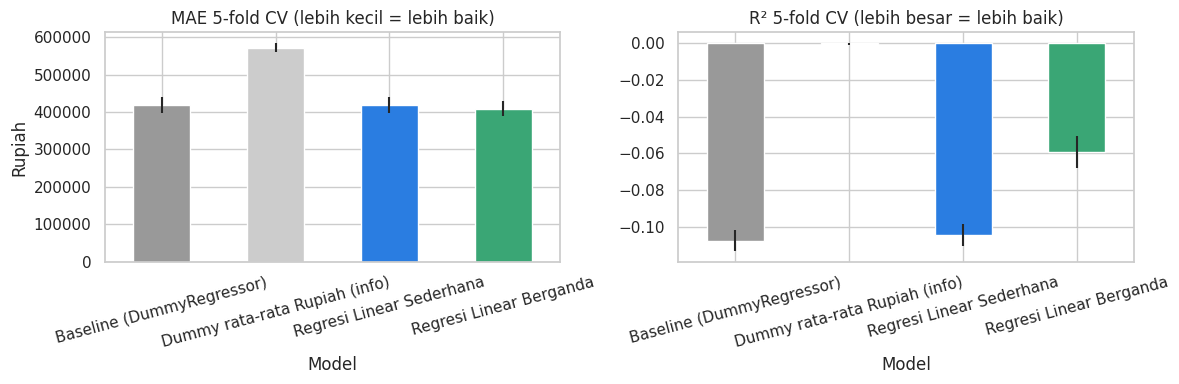

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cv_tabel["MAE CV (rata2)"].plot.bar(yerr=cv_tabel["MAE CV (std)"], ax=ax[0], color=["#999", "#ccc", "#2a7de1", "#3aa675"], rot=15)
ax[0].set_title("MAE 5-fold CV (lebih kecil = lebih baik)"); ax[0].set_ylabel("Rupiah")
cv_tabel["R2 CV (rata2)"].plot.bar(yerr=cv_tabel["R2 CV (std)"], ax=ax[1], color=["#999", "#ccc", "#2a7de1", "#3aa675"], rot=15)
ax[1].set_title("R² 5-fold CV (lebih besar = lebih baik)")
plt.tight_layout(); plt.show()

### Keputusan saya (Tahap 4)
- Saya membangun **tiga model** sesuai Jalur B: baseline `DummyRegressor` (selalu menebak rata-rata harga), regresi linear sederhana (1 fitur: yang korelasinya paling kuat dengan target pada data latih), dan regresi linear berganda (semua fitur terpilih, ≥2).
- Perbandingan dilakukan dengan **5-fold CV (`KFold`, shuffle, `random_state=SEED`) pada data latih saja**; data uji belum disentuh.
- Karena harga sangat miring, model dilatih pada **log(harga)** lewat `TransformedTargetRegressor`; prediksi dikembalikan ke Rupiah sehingga MAE/RMSE tetap berarti dalam Rupiah.
- Baseline utama saya buat **dengan transformasi log yang sama** seperti model lain agar perbandingannya adil (tanpa itu, model log otomatis tampak lebih baik hanya karena memprediksi mendekati median). Baseline rata-rata Rupiah mentah tetap ditampilkan sebagai informasi tambahan.

In [20]:
# Ringkasan hasil CV (ditulis otomatis dari angka)
b = cv_tabel.loc["Baseline (DummyRegressor)"]
for nama in ["Regresi Linear Sederhana", "Regresi Linear Berganda"]:
    r = cv_tabel.loc[nama]
    print(f"{nama}: MAE CV Rp {r['MAE CV (rata2)']:,.0f} (baseline Rp {b['MAE CV (rata2)']:,.0f}, selisih {(1 - r['MAE CV (rata2)']/b['MAE CV (rata2)']):+.1%}); "
          f"R² CV {r['R2 CV (rata2)']:.3f} (baseline {b['R2 CV (rata2)']:.3f}).")
print("Simpangan baku antar-fold kecil -> skor stabil" if cv_tabel['MAE CV (std)'].max() < 0.1 * cv_tabel['MAE CV (rata2)'].min() else "Simpangan baku antar-fold cukup besar -> skor kurang stabil")

Regresi Linear Sederhana: MAE CV Rp 418,693 (baseline Rp 419,242, selisih +0.1%); R² CV -0.104 (baseline -0.107).
Regresi Linear Berganda: MAE CV Rp 409,002 (baseline Rp 419,242, selisih +2.4%); R² CV -0.059 (baseline -0.107).
Simpangan baku antar-fold kecil -> skor stabil


# 5. Evaluasi dan Interpretasi (Evaluation)

Setiap model **diuji satu kali** pada data uji.

In [21]:
def metrik(model, X_, y_):
    p = model.predict(X_)
    return {"MAE": mean_absolute_error(y_, p),
            "RMSE": np.sqrt(mean_squared_error(y_, p)),
            "R2": r2_score(y_, p),
            "R2log": r2_score(np.log1p(y_), np.log1p(np.clip(p, 0, None)))}

hasil, preds = [], {}
for nama, m in models.items():
    m.fit(X_train, y_train)
    tr, te = metrik(m, X_train, y_train), metrik(m, X_test, y_test)
    preds[nama] = m.predict(X_test)
    hasil.append({"Model": nama, "R2 latih (skala log)": tr["R2log"],
                  "MAE latih": tr["MAE"], "MAE uji": te["MAE"],
                  "RMSE uji": te["RMSE"],
                  "R2 latih": tr["R2"], "R2 uji": te["R2"], "R2 uji (skala log)": te["R2log"],
                  "Selisih R2 log (latih-uji)": tr["R2log"] - te["R2log"]})
tabel_akhir = pd.DataFrame(hasil).set_index("Model")
tabel_akhir

,R2 latih (skala log),MAE latih,MAE uji,RMSE uji,R2 latih,R2 uji,R2 uji (skala log),Selisih R2 log (latih-uji)
Model,,,,,,,,
Baseline (DummyRegressor),0.00,"419,220.11","407,233.65","1,107,532.41",-0.11,-0.10,-0.00,0.00
Dummy rata-rata Rupiah (info),-0.73,"571,299.87","565,291.52","1,056,239.81",0.00,-0.00,-0.77,0.04
Regresi Linear Sederhana,0.01,"418,670.75","406,849.86","1,106,287.63",-0.10,-0.10,0.00,0.00
Regresi Linear Berganda,0.14,"408,219.16","396,465.70","1,083,983.29",-0.06,-0.05,0.13,0.02


In [22]:
# Tafsir MAE dalam satuan target (Rupiah)
med = y_test.median()
for nama in tabel_akhir.index:
    mae = tabel_akhir.loc[nama, "MAE uji"]
    print(f"{nama:28s}: rata-rata prediksi meleset Rp {mae:,.0f} (≈ {mae/med:.0%} dari median harga uji Rp {med:,.0f})")

Baseline (DummyRegressor)   : rata-rata prediksi meleset Rp 407,234 (≈ 418% dari median harga uji Rp 97,350)
Dummy rata-rata Rupiah (info): rata-rata prediksi meleset Rp 565,292 (≈ 581% dari median harga uji Rp 97,350)
Regresi Linear Sederhana    : rata-rata prediksi meleset Rp 406,850 (≈ 418% dari median harga uji Rp 97,350)
Regresi Linear Berganda     : rata-rata prediksi meleset Rp 396,466 (≈ 407% dari median harga uji Rp 97,350)


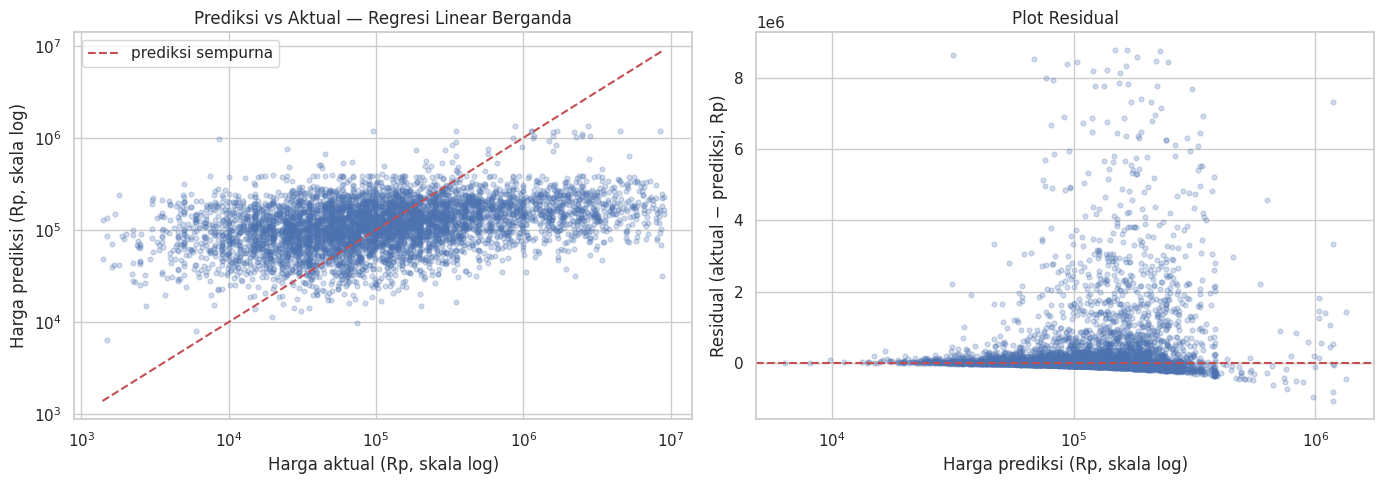

In [23]:
# Plot prediksi vs aktual dan plot residual — model terbaik (berganda)
nm = "Regresi Linear Berganda"
yp = preds[nm]
resid = y_test.values - yp
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_test, yp, alpha=0.25, s=12)
lim = [min(y_test.min(), yp.min()), max(y_test.max(), yp.max())]
ax[0].plot(lim, lim, "r--", label="prediksi sempurna")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Harga aktual (Rp, skala log)"); ax[0].set_ylabel("Harga prediksi (Rp, skala log)")
ax[0].set_title("Prediksi vs Aktual — " + nm); ax[0].legend()
ax[1].scatter(yp, resid, alpha=0.25, s=12)
ax[1].axhline(0, color="r", ls="--")
ax[1].set_xscale("log"); ax[1].set_xlabel("Harga prediksi (Rp, skala log)"); ax[1].set_ylabel("Residual (aktual − prediksi, Rp)")
ax[1].set_title("Plot Residual")
plt.tight_layout(); plt.show()

In [24]:
# Arti koefisien regresi berganda
m_b = models["Regresi Linear Berganda"]
reg_b = m_b.regressor_ if USE_LOG else m_b
nama_fitur = reg_b.named_steps["pre"].get_feature_names_out()
koef = pd.DataFrame({"fitur": nama_fitur, "koefisien": reg_b.named_steps["reg"].coef_})
if USE_LOG:
    koef["perubahan harga (%) per +1 SD"] = (np.exp(koef["koefisien"]) - 1) * 100
koef = koef.reindex(koef["koefisien"].abs().sort_values(ascending=False).index)
print("Intercept (skala", "log" if USE_LOG else "Rupiah", "):", round(float(reg_b.named_steps["reg"].intercept_), 4))
koef_num = koef[koef["fitur"].str.startswith("num__")].copy()
if CAT_FEATURES:
    kolom_kat = CAT_FEATURES[0]
    n_kota = X_train[kolom_kat].value_counts()
    koef["n_latih"] = koef["fitur"].map(
        lambda f: int(n_kota.get(f.split("__", 1)[1].replace(kolom_kat + "_", "", 1), 0)) if f.startswith("cat__") else np.nan)
print("Koefisien fitur numerik (per +1 simpangan baku dari log-fitur):")
display(koef_num)
if CAT_FEATURES:
    print("\nKoefisien lokasi (hanya kota dengan >= 50 data latih; kota berdata sedikit koefisiennya tidak stabil):")
    display(koef[koef["fitur"].str.startswith("cat__") & (koef["n_latih"] >= 50)].head(10))

Intercept (skala log ): 11.4931
Koefisien fitur numerik (per +1 simpangan baku dari log-fitur):


,fitur,koefisien,perubahan harga (%) per +1 SD
0,num__terjual,-0.58,-43.97
2,num__rating,0.15,16.38
1,num__jumlah_ulasan,0.09,9.41
3,num__diskon,-0.01,-0.52



Koefisien lokasi (hanya kota dengan >= 50 data latih; kota berdata sedikit koefisiennya tidak stabil):


,fitur,koefisien,perubahan harga (%) per +1 SD,n_latih
30,cat__lokasi_toko_kab. jepara,1.78,495.54,108.00
34,cat__lokasi_toko_kab. klaten,1.34,283.10,61.00
74,cat__lokasi_toko_palembang,1.04,182.06,61.00
70,cat__lokasi_toko_kota yogyakarta,-0.70,-50.10,55.00
20,cat__lokasi_toko_kab. bandung barat,-0.57,-43.61,63.00
12,cat__lokasi_toko_jakarta,0.54,71.89,"3,118.00"
49,cat__lokasi_toko_kota administrasi jakarta sel...,0.53,69.49,151.00
14,cat__lokasi_toko_jakarta pusat,0.53,69.06,"1,145.00"
48,cat__lokasi_toko_kota administrasi jakarta pusat,0.52,68.73,226.00
84,cat__lokasi_toko_yogyakarta,0.47,59.64,86.00


In [25]:
# Interpretasi hasil evaluasi (ditulis otomatis dari angka)
B, S, G = (tabel_akhir.loc[k] for k in ["Baseline (DummyRegressor)", "Regresi Linear Sederhana", "Regresi Linear Berganda"])
yp = preds["Regresi Linear Berganda"]
dalam50 = np.mean(np.abs(yp - y_test.values) / y_test.values <= 0.5)

print("INTERPRETASI")
print(f"- MAE: model berganda rata-rata meleset Rp {G['MAE uji']:,.0f} pada data uji (≈ {G['MAE uji']/y_test.median():.0%} dari median harga uji Rp {y_test.median():,.0f}); "
      f"baseline meleset Rp {B['MAE uji']:,.0f}. Selisihnya {(1 - G['MAE uji']/B['MAE uji']):+.1%} terhadap baseline.")
print(f"- RMSE: {G['RMSE uji']:,.0f} (baseline {B['RMSE uji']:,.0f}); RMSE lebih besar dari MAE karena kesalahan besar pada produk mahal dihukum lebih berat.")
print(f"- R²: pada skala Rupiah R² uji = {G['R2 uji']:.3f} (baseline {B['R2 uji']:.3f}); pada skala log R² uji = {G['R2 uji (skala log)']:.3f} (baseline {B['R2 uji (skala log)']:.3f}). "
      f"Artinya model berganda menjelaskan sekitar {max(G['R2 uji (skala log)'],0):.0%} variasi log-harga.")
print(f"- Ketepatan praktis: {dalam50:.0%} prediksi model berganda berada dalam ±50% dari harga sebenarnya.")
print(f"- Sederhana vs berganda: MAE uji {S['MAE uji']:,.0f} vs {G['MAE uji']:,.0f}; R² log {S['R2 uji (skala log)']:.3f} vs {G['R2 uji (skala log)']:.3f}.")

gap = G["Selisih R2 log (latih-uji)"]
print(f"- Overfitting: R² log latih {G['R2 latih (skala log)']:.3f} vs uji {G['R2 uji (skala log)']:.3f} (selisih {gap:+.3f}) -> "
      + ("ada indikasi overfitting." if gap > 0.05 else "tidak ada overfitting berarti; model linear sederhana cenderung stabil (justru cenderung underfitting karena fiturnya terbatas)."))

print("- Koefisien fitur numerik (per +1 simpangan baku dari log-fitur, fitur lain tetap):")
for _, r in koef_num.iterrows():
    nm_ = r["fitur"].replace("num__", "")
    if USE_LOG:
        arah = "naik" if r["koefisien"] > 0 else "turun"
        print(f"    * {nm_}: harga {arah} sekitar {abs(r['perubahan harga (%) per +1 SD']):.1f}% (koefisien {r['koefisien']:+.3f})")
    else:
        print(f"    * {nm_}: {r['koefisien']:+,.0f} Rupiah")
if CAT_FEATURES:
    kota = koef[koef["fitur"].str.startswith("cat__") & (koef["n_latih"] >= 50)]
    if len(kota):
        atas, bawah = kota.sort_values("koefisien").iloc[-1], kota.sort_values("koefisien").iloc[0]
        print(f"- Lokasi (kota dengan >= 50 data latih): harga relatif paling tinggi di {atas['fitur'].split('__',1)[1].replace(CAT_FEATURES[0]+'_','',1)} "
              f"dan paling rendah di {bawah['fitur'].split('__',1)[1].replace(CAT_FEATURES[0]+'_','',1)}; kota dengan data sangat sedikit tidak saya tafsirkan karena koefisiennya tidak stabil.")
print("  Ini hubungan asosiasi, bukan sebab-akibat.")
print(f"- Plot: titik prediksi vs aktual {'cukup mengikuti' if G['R2 uji (skala log)'] > 0.3 else 'menyebar lebar dari'} garis diagonal; "
      f"residual {'relatif acak' if abs(np.corrcoef(yp, y_test.values - yp)[0,1]) < 0.3 else 'masih berpola terhadap nilai prediksi'}, "
      f"dengan kesalahan terbesar pada produk berharga tinggi.")

INTERPRETASI
- MAE: model berganda rata-rata meleset Rp 396,466 pada data uji (≈ 407% dari median harga uji Rp 97,350); baseline meleset Rp 407,234. Selisihnya +2.6% terhadap baseline.
- RMSE: 1,083,983 (baseline 1,107,532); RMSE lebih besar dari MAE karena kesalahan besar pada produk mahal dihukum lebih berat.
- R²: pada skala Rupiah R² uji = -0.053 (baseline -0.100); pada skala log R² uji = 0.127 (baseline -0.000). Artinya model berganda menjelaskan sekitar 13% variasi log-harga.
- Ketepatan praktis: 29% prediksi model berganda berada dalam ±50% dari harga sebenarnya.
- Sederhana vs berganda: MAE uji 406,850 vs 396,466; R² log 0.005 vs 0.127.
- Overfitting: R² log latih 0.142 vs uji 0.127 (selisih +0.015) -> tidak ada overfitting berarti; model linear sederhana cenderung stabil (justru cenderung underfitting karena fiturnya terbatas).
- Koefisien fitur numerik (per +1 simpangan baku dari log-fitur, fitur lain tetap):
    * terjual: harga turun sekitar 44.0% (koefisien -0.579)
    * r

### Keputusan saya (Tahap 5)
Saya menilai model dengan tiga metrik: **MAE** (mudah dibaca dalam Rupiah), **RMSE** (menghukum kesalahan besar) dan **R²** (proporsi variasi yang dijelaskan; saya laporkan pada skala Rupiah dan skala log karena model dilatih pada log-harga). Data uji dipakai **satu kali**, setelah semua keputusan modeling selesai di Tahap 4, agar skor uji tidak terlalu optimistis.

# 6. Kesimpulan (Deployment/Rekomendasi)

In [26]:
# Pemilihan model & kesimpulan (ditulis otomatis dari angka hasil)
B = tabel_akhir.loc["Baseline (DummyRegressor)"]
kandidat_model = ["Regresi Linear Sederhana", "Regresi Linear Berganda"]
# Model dipilih berdasarkan MAE cross-validation (data latih), BUKAN skor uji -> menghindari 'mengintip' data uji
terbaik = cv_tabel.loc[kandidat_model, "MAE CV (rata2)"].idxmin()
T = tabel_akhir.loc[terbaik]

turun_mae = 1 - T["MAE uji"] / B["MAE uji"]
naik_r2log = T["R2 uji (skala log)"] - B["R2 uji (skala log)"]
layak = (turun_mae >= 0.05) and (T["R2 uji (skala log)"] >= 0.10)

print(f"Model terpilih (MAE CV terendah): {terbaik}\n")
print("ALASAN BERBASIS ANGKA")
print(f"1) MAE uji Rp {T['MAE uji']:,.0f} vs baseline Rp {B['MAE uji']:,.0f} (selisih {turun_mae:+.1%}).")
print(f"2) R² uji skala log {T['R2 uji (skala log)']:.3f} vs baseline {B['R2 uji (skala log)']:.3f} (naik {naik_r2log:+.3f}); R² skala Rupiah {T['R2 uji']:.3f}.")
print(f"3) Skor CV konsisten dengan skor uji: MAE CV Rp {cv_tabel.loc[terbaik, 'MAE CV (rata2)']:,.0f} vs MAE uji Rp {T['MAE uji']:,.0f}.")
print(f"4) Selisih R² log latih–uji {T['Selisih R2 log (latih-uji)']:+.3f} -> {'ada indikasi overfitting' if T['Selisih R2 log (latih-uji)'] > 0.05 else 'tidak overfitting'}.")
print(f"5) Berganda vs sederhana: MAE uji Rp {tabel_akhir.loc['Regresi Linear Berganda','MAE uji']:,.0f} vs Rp {tabel_akhir.loc['Regresi Linear Sederhana','MAE uji']:,.0f}.\n")

if layak:
    print("KESIMPULAN: model LAYAK dipakai dibanding baseline sebagai estimasi kasar harga (turun MAE >= 5% dan R² log >= 0,10), "
          "tetapi masih memiliki kesalahan yang besar sehingga hanya cocok sebagai titik awal/pembanding.")
else:
    print("KESIMPULAN: model BELUM layak dipakai sebagai prediktor harga yang andal. Perbaikannya terhadap baseline kecil "
          f"(MAE {turun_mae:+.1%}, R² log {T['R2 uji (skala log)']:.3f}); fitur yang tersedia (rating, diskon, penjualan, ulasan, lokasi) "
          "belum cukup menjelaskan variasi harga. Kemungkinan besar harga lebih ditentukan oleh jenis/merek produk yang tidak ada di data; ini temuan yang sah dan dibahas di keterbatasan.")

Model terpilih (MAE CV terendah): Regresi Linear Berganda

ALASAN BERBASIS ANGKA
1) MAE uji Rp 396,466 vs baseline Rp 407,234 (selisih +2.6%).
2) R² uji skala log 0.127 vs baseline -0.000 (naik +0.127); R² skala Rupiah -0.053.
3) Skor CV konsisten dengan skor uji: MAE CV Rp 409,002 vs MAE uji Rp 396,466.
4) Selisih R² log latih–uji +0.015 -> tidak overfitting.
5) Berganda vs sederhana: MAE uji Rp 396,466 vs Rp 406,850.

KESIMPULAN: model BELUM layak dipakai sebagai prediktor harga yang andal. Perbaikannya terhadap baseline kecil (MAE +2.6%, R² log 0.127); fitur yang tersedia (rating, diskon, penjualan, ulasan, lokasi) belum cukup menjelaskan variasi harga. Kemungkinan besar harga lebih ditentukan oleh jenis/merek produk yang tidak ada di data; ini temuan yang sah dan dibahas di keterbatasan.


**Rekomendasi bagi pengguna.**
- Penjual UMKM dapat memakai model ini hanya sebagai **pembanding kasar** (rentang harga ≈ prediksi ± MAE), bukan penentu harga. Jika harga produk jauh di luar rentang prediksi, jadikan itu sinyal untuk mengecek harga pesaing sejenis.
- Untuk penentuan harga yang sebenarnya, bandingkan dengan produk **sekategori** (nama produk/kategori yang sama), karena itu faktor terbesar yang tidak ada di model ini.

**Keterbatasan.**
- Fitur terbatas: **jenis/kategori produk, merek, ukuran/berat, dan kualitas** tidak tersedia sebagai fitur, padahal sangat menentukan harga.
- Data adalah satu potret waktu hasil scraping; harga marketplace berubah (promo, musim) dan produk populer bisa lebih terwakili.
- Model linear mengasumsikan hubungan lurus (pada skala log); hubungan nyata kemungkinan non-linear.
- Harga di luar rentang IQR dibuang, sehingga model **tidak berlaku** untuk produk sangat murah/sangat mahal.
- Koefisien hanya menunjukkan asosiasi, bukan sebab-akibat.

**Saran perbaikan.**
- Ekstrak fitur dari **nama produk** (TF-IDF atau kata kunci kategori) dan tambahkan kategori produk.
- Bandingkan dengan model non-linear (Random Forest / Gradient Boosting) dan regularisasi (Ridge/Lasso).
- Gunakan data dari beberapa periode waktu dan lakukan analisis per kategori produk.

### Keputusan saya (Tahap 6)
Model akhir dipilih berdasarkan **skor cross-validation pada data latih**, bukan skor uji, lalu data uji dipakai satu kali untuk konfirmasi. Kesimpulan kelayakan memakai ambang yang saya tetapkan sebelumnya (penurunan MAE ≥ 5% dan R² skala log ≥ 0,10 terhadap baseline) agar penilaian tidak bergantung selera. Keterbatasan saya tulis terbuka supaya hasil tidak disalahartikan sebagai prediksi harga yang pasti.